In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dataset location
file_path = r"C:\MyDrive\Learn\MoodDriveAI\data\dataset2\allcars.csv"

# Load first 1000 records
sample = pd.read_csv(file_path, nrows=1000)

# Display first five records
display(sample.head())

,Unnamed: 0,timeStamp,tripID,accData,gps_speed,battery,cTemp,dtc,eLoad,iat,imap,kpl,maf,rpm,speed,tAdv,tPos,deviceID
0,0,2017-10-31 18:45:59.000000,0,ffb0fd700220fff43fffe74808e73e03f33400ef33fbe1...,2.2,14.48,NaN,NaN,44.313725,NaN,NaN,0.0,0.0,903.0,4,NaN,15.686275,1
1,1,2017-10-31 18:46:00.000000,0,00b0fda802e804e14104ed3d01ee3a08ec4c04f738fbd5...,3.7,14.48,NaN,NaN,35.294118,NaN,NaN,0.0,0.0,938.0,6,NaN,15.294118,1
2,2,2017-10-31 18:46:01.000000,0,00f0fe5002b0fdea4009e33c01ed3701ec4100f53b05e8...,3.9,14.54,NaN,NaN,29.411765,NaN,NaN,0.0,0.0,1044.5,7,NaN,14.901961,1
3,3,2017-10-31 18:46:02.000000,0,0120fdc0028804e03c10de3a09e8400ce43b0ae63b01f4...,3.9,14.56,NaN,NaN,53.725490,NaN,NaN,0.0,0.0,1102.0,7,NaN,17.647059,1
4,4,2017-10-31 18:46:03.000000,0,00a0fde802d816e0370ae73604e23b04e53900e542ffea...,4.7,14.48,NaN,NaN,75.686275,NaN,NaN,0.0,0.0,1626.5,10,NaN,23.529412,1


In [2]:
# Dataset dimensions
print("Dataset Shape:", sample.shape)

# Column names
print("\nColumn Names:")
print(sample.columns.tolist())

# Dataset information
print("\nDataset Information:")
sample.info()

# Missing values
print("\nMissing Values:")
print(sample.isnull().sum())

Dataset Shape: (1000, 18)

Column Names:
['Unnamed: 0', 'timeStamp', 'tripID', 'accData', 'gps_speed', 'battery', 'cTemp', 'dtc', 'eLoad', 'iat', 'imap', 'kpl', 'maf', 'rpm', 'speed', 'tAdv', 'tPos', 'deviceID']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  1000 non-null   int64  
 1   timeStamp   1000 non-null   object 
 2   tripID      1000 non-null   int64  
 3   accData     1000 non-null   object 
 4   gps_speed   1000 non-null   float64
 5   battery     1000 non-null   float64
 6   cTemp       0 non-null      float64
 7   dtc         0 non-null      float64
 8   eLoad       1000 non-null   float64
 9   iat         0 non-null      float64
 10  imap        0 non-null      float64
 11  kpl         1000 non-null   float64
 12  maf         1000 non-null   float64
 13  rpm         1000 non-null   float64
 14 

In [3]:
# Convert timestamp into datetime format
sample['timeStamp'] = pd.to_datetime(sample['timeStamp'])

# Calculate differences between consecutive timestamps
time_diff = sample['timeStamp'].diff()

print("First 20 Time Intervals:")
print(time_diff.head(20))

print("\nMost Common Sampling Intervals:")
print(time_diff.value_counts().head(10))

First 20 Time Intervals:
0                NaT
1    0 days 00:00:01
2    0 days 00:00:01
3    0 days 00:00:01
4    0 days 00:00:01
5    0 days 00:00:01
6    0 days 00:00:01
7    0 days 00:00:01
8    0 days 00:00:01
9    0 days 00:00:01
10   0 days 00:00:01
11   0 days 00:00:01
12   0 days 00:00:01
13   0 days 00:00:01
14   0 days 00:00:01
15   0 days 00:00:01
16   0 days 00:00:01
17   0 days 00:00:01
18   0 days 00:00:01
19   0 days 00:00:01
Name: timeStamp, dtype: timedelta64[ns]

Most Common Sampling Intervals:
timeStamp
0 days 00:00:01    997
9 days 02:10:05      1
0 days 00:00:02      1
Name: count, dtype: int64


In [4]:
# Calculate sampling interval statistics
print("Median Interval:", time_diff.median())
print("Minimum Interval:", time_diff.min())
print("Maximum Interval:", time_diff.max())

print("\nUnique Sampling Intervals:")
print(time_diff.value_counts())

Median Interval: 0 days 00:00:01
Minimum Interval: 0 days 00:00:01
Maximum Interval: 9 days 02:10:05

Unique Sampling Intervals:
timeStamp
0 days 00:00:01    997
9 days 02:10:05      1
0 days 00:00:02      1
Name: count, dtype: int64


In [5]:
# Find intervals greater than one second
irregular = time_diff[time_diff > pd.Timedelta(seconds=1)]

print("Irregular Timestamp Intervals:")

for idx in irregular.index:

    print("\nCurrent Record:")
    print(sample.loc[idx, ['timeStamp', 'tripID']])

    print("\nPrevious Record:")
    print(sample.loc[idx - 1, ['timeStamp', 'tripID']])

Irregular Timestamp Intervals:

Current Record:
timeStamp    2017-11-09 21:01:15
tripID                         0
Name: 312, dtype: object

Previous Record:
timeStamp    2017-10-31 18:51:10
tripID                         0
Name: 311, dtype: object

Current Record:
timeStamp    2017-11-09 21:05:30
tripID                         0
Name: 566, dtype: object

Previous Record:
timeStamp    2017-11-09 21:05:28
tripID                         0
Name: 565, dtype: object


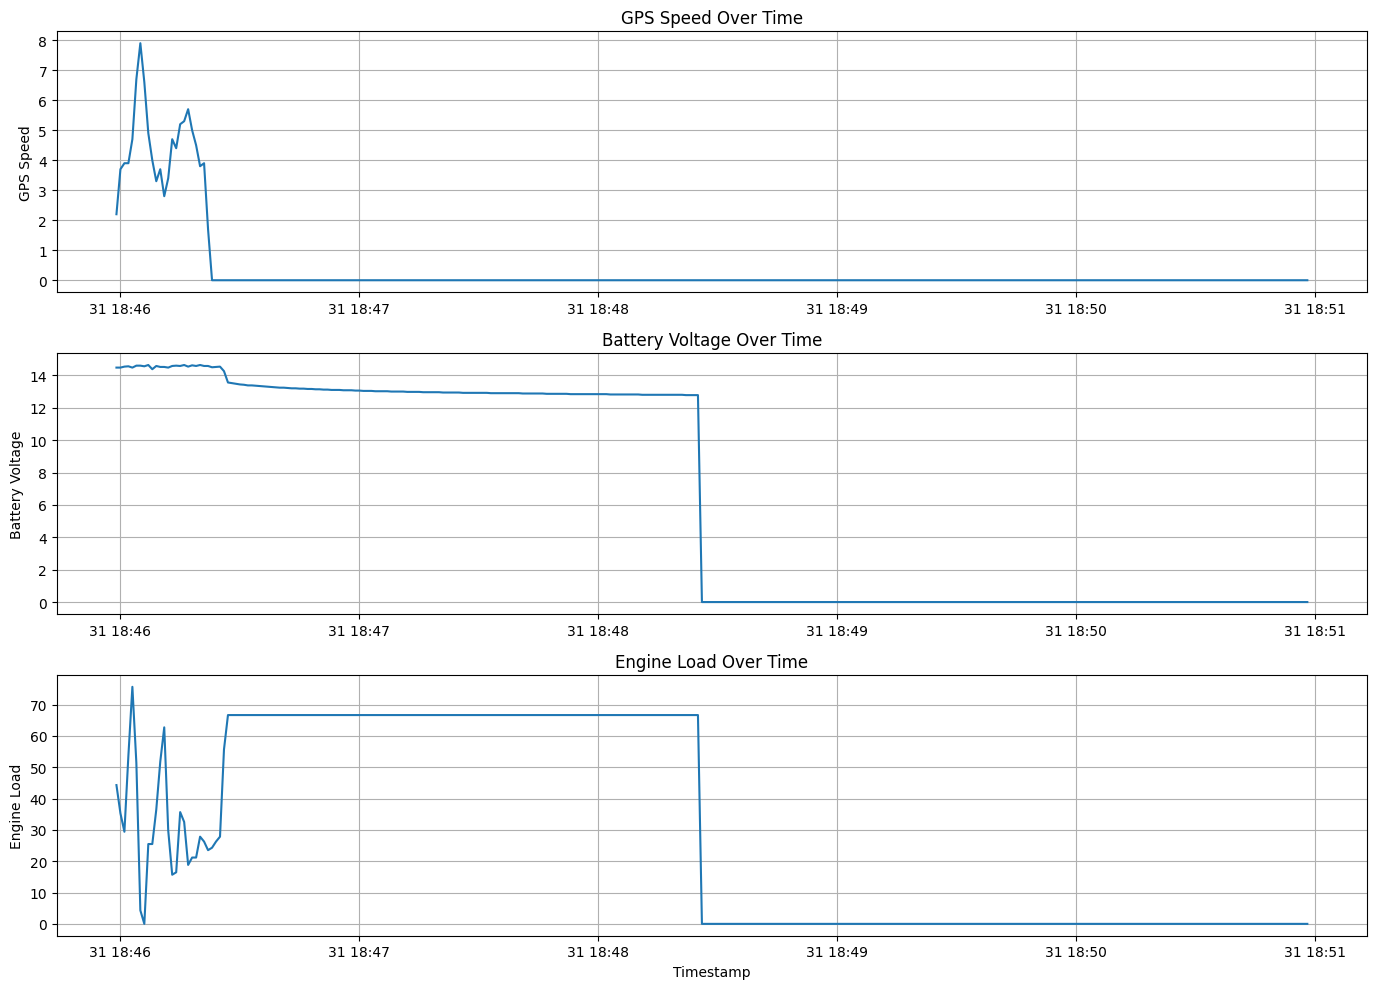

In [6]:
# Select first 300 records
plot_sample = sample.sort_values('timeStamp').iloc[:300].copy()

# Create three separate plots
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# GPS Speed
axes[0].plot(plot_sample['timeStamp'], plot_sample['gps_speed'])
axes[0].set_title('GPS Speed Over Time')
axes[0].set_ylabel('GPS Speed')
axes[0].grid(True)

# Battery Voltage
axes[1].plot(plot_sample['timeStamp'], plot_sample['battery'])
axes[1].set_title('Battery Voltage Over Time')
axes[1].set_ylabel('Battery Voltage')
axes[1].grid(True)

# Engine Load
axes[2].plot(plot_sample['timeStamp'], plot_sample['eLoad'])
axes[2].set_title('Engine Load Over Time')
axes[2].set_ylabel('Engine Load')
axes[2].set_xlabel('Timestamp')
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [7]:
# Check zero and missing values
columns = ['gps_speed', 'battery', 'eLoad']

for col in columns:

    print(f"\n{col}")

    print("Zero Values:", (plot_sample[col] == 0).sum())

    print("Non-Zero Values:", (plot_sample[col] != 0).sum())

    print("Missing Values:", plot_sample[col].isna().sum())

    print("Minimum:", plot_sample[col].min())

    print("Maximum:", plot_sample[col].max())


gps_speed
Zero Values: 276
Non-Zero Values: 24
Missing Values: 0
Minimum: 0.0
Maximum: 7.9

battery
Zero Values: 153
Non-Zero Values: 147
Missing Values: 0
Minimum: 0.0
Maximum: 14.64

eLoad
Zero Values: 154
Non-Zero Values: 146
Missing Values: 0
Minimum: 0.0
Maximum: 75.68627450980392


In [8]:
# Inspect records around the sudden changes
display(
    plot_sample.loc[140:155, [
        'timeStamp',
        'tripID',
        'gps_speed',
        'battery',
        'eLoad'
    ]]
)

,timeStamp,tripID,gps_speed,battery,eLoad
140,2017-10-31 18:48:19,0,0.0,12.80,66.666667
141,2017-10-31 18:48:20,0,0.0,12.80,66.666667
142,2017-10-31 18:48:21,0,0.0,12.80,66.666667
143,2017-10-31 18:48:22,0,0.0,12.78,66.666667
144,2017-10-31 18:48:23,0,0.0,12.78,66.666667
145,2017-10-31 18:48:24,0,0.0,12.78,66.666667
146,2017-10-31 18:48:25,0,0.0,12.78,66.666667
147,2017-10-31 18:48:26,0,0.0,0.00,0.000000
148,2017-10-31 18:48:27,0,0.0,0.00,0.000000
149,2017-10-31 18:48:28,0,0.0,0.00,0.000000


In [9]:
for col in ['gps_speed', 'battery', 'eLoad']:

    zero_indices = plot_sample.index[
        plot_sample[col] == 0
    ]

    nonzero_indices = plot_sample.index[
        plot_sample[col] != 0
    ]

    print(f"\n{col}")

    print(
        "First Zero Index:",
        zero_indices.min() if len(zero_indices) else None
    )

    print(
        "Last Non-Zero Index:",
        nonzero_indices.max() if len(nonzero_indices) else None
    )

    print(
        "Zero Percentage:",
        round((plot_sample[col] == 0).mean() * 100, 2),
        "%"
    )


gps_speed
First Zero Index: 24
Last Non-Zero Index: 23
Zero Percentage: 92.0 %

battery
First Zero Index: 147
Last Non-Zero Index: 146
Zero Percentage: 51.0 %

eLoad
First Zero Index: 7
Last Non-Zero Index: 146
Zero Percentage: 51.33 %
